# M04-L03 — CNNs: Imagem como Tensor, Convolução e Pooling

## Antes de começar: nesta lição o dataset muda de verdade

Até a M04-L02, você trabalhava com `df_features`: cada fotografia já tinha sido resumida em alguns números. **Nesta é a primeira lição em que vamos usar diretamente o dataset de imagens Iris Computer Vision**, disponível no Kaggle:

https://www.kaggle.com/datasets/jeffheaton/iris-computer-vision

Por isso, antes de falar de convolução, precisamos preparar os dados com calma. O notebook fará três coisas para você:

1. **baixar e extrair** o dataset no Colab;
2. **contar quantas imagens existem em cada classe**;
3. como o conjunto original é desbalanceado, usar em `setosa`, `versicolor` e `virginica` **a mesma quantidade de imagens: o número de imagens da menor classe**. As imagens excedentes das classes maiores ficam de fora deste laboratório.

Essa escolha é um *undersampling* simples. Ela perde parte dos dados das classes maiores, mas deixa a comparação entre as três classes mais direta para este primeiro contato com CNNs. Depois de equilibrar as classes, o notebook cria as partições `train`, `val` e `test` de forma reprodutível.

> **Importante:** você não precisa saber de antemão quantas imagens há em cada classe. O código vai contar e imprimir as quantidades. O valor usado será calculado automaticamente com `min(...)`.

### Se o download automático não funcionar

O dataset é público e o notebook tenta baixá-lo diretamente. Se o Colab bloquear o download por algum motivo, abra o link acima, clique em **Download**, envie o arquivo `.zip` para a sessão do Colab e coloque o nome dele em `ARQUIVO_ZIP` na célula de preparação.

**Orientações gerais:**

1. Salve uma cópia deste notebook no Google Drive (`Arquivo > Salvar uma cópia no Drive`).
2. Execute as células **na ordem**, de cima para baixo.
3. Não crie manualmente as pastas `train`, `val` e `test`: as células de preparação fazem isso.
4. Ao final, entregue o notebook executado e os `.csv` gerados.


In [1]:
from pathlib import Path
import random
import shutil
import urllib.request
import zipfile

import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

torch.manual_seed(42)


## 1. Preparando o Iris Computer Vision

### 1.1 Baixar e extrair

O link normal do Kaggle é útil para você abrir a página e conhecer a fonte. Para o notebook, usamos o endpoint público de download do próprio Kaggle. O arquivo é salvo como `.zip` e extraído para `iris_raw/`.

A célula verifica primeiro se o `.zip` já existe. Isso é útil caso você tenha precisado fazer o download manual e enviado o arquivo para o Colab.


In [2]:
KAGGLE_DOWNLOAD_URL = "https://www.kaggle.com/api/v1/datasets/download/jeffheaton/iris-computer-vision"
ARQUIVO_ZIP = Path("iris-computer-vision.zip")
PASTA_RAW = Path("iris_raw")

if not PASTA_RAW.exists():
    if not ARQUIVO_ZIP.exists():
        print("Baixando o dataset do Kaggle...")
        urllib.request.urlretrieve(KAGGLE_DOWNLOAD_URL, ARQUIVO_ZIP)

    print("Extraindo o dataset...")
    PASTA_RAW.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(ARQUIVO_ZIP, "r") as arquivo:
        arquivo.extractall(PASTA_RAW)
else:
    print("A pasta iris_raw/ já existe; o download não será repetido.")

print("Dataset bruto disponível em:", PASTA_RAW.resolve())


Baixando o dataset do Kaggle...
Extraindo o dataset...
Dataset bruto disponível em: /content/iris_raw


### 1.2 Descobrir as classes e conferir o desbalanceamento

No arquivo original, os nomes das pastas podem aparecer como `iris-setosa`, `iris-versicolour` e `iris-virginica`. No restante do curso vamos padronizar os nomes como `setosa`, `versicolor` e `virginica`.

Primeiro apenas **contamos** as imagens. Observe a saída e identifique qual é a menor classe. Em seguida, o código calcula `n_por_classe`, que será exatamente essa menor quantidade.


In [3]:
EXTENSOES_IMAGEM = {".jpg", ".jpeg", ".png", ".bmp", ".gif", ".tif", ".tiff"}

ALIASES = {
    "setosa": {"setosa", "iris-setosa"},
    "versicolor": {"versicolor", "versicolour", "iris-versicolor", "iris-versicolour"},
    "virginica": {"virginica", "iris-virginica"},
}

def localizar_pasta_classe(base, aliases):
    candidatos = [
        pasta for pasta in base.rglob("*")
        if pasta.is_dir() and pasta.name.lower() in aliases
    ]
    if not candidatos:
        raise FileNotFoundError(f"Não encontrei nenhuma pasta compatível com: {sorted(aliases)}")
    return candidatos[0]

def listar_imagens(pasta):
    return sorted([
        arquivo for arquivo in pasta.rglob("*")
        if arquivo.is_file() and arquivo.suffix.lower() in EXTENSOES_IMAGEM
    ])

pastas_origem = {
    classe: localizar_pasta_classe(PASTA_RAW, aliases)
    for classe, aliases in ALIASES.items()
}

quantidades_originais = {
    classe: len(listar_imagens(pasta))
    for classe, pasta in pastas_origem.items()
}

for classe, quantidade in quantidades_originais.items():
    print(f"{classe:10s}: {quantidade} imagens")

n_por_classe = min(quantidades_originais.values())
print("\nMenor classe:", n_por_classe, "imagens")
print("Usaremos", n_por_classe, "imagens de CADA classe antes da divisão treino/val/teste.")


setosa    : 67 imagens
versicolor: 269 imagens
virginica : 85 imagens

Menor classe: 67 imagens
Usaremos 67 imagens de CADA classe antes da divisão treino/val/teste.


### 1.3 Criar um conjunto balanceado e dividir em treino, validação e teste

Agora fazemos duas decisões importantes:

- de cada classe, selecionamos somente `n_por_classe` imagens;
- essas imagens são divididas aproximadamente em **70% treino, 15% validação e 15% teste**.

Usamos a mesma semente (`42`) para que, ao executar o notebook novamente, a seleção e a divisão sejam reproduzíveis. Como começamos com a mesma quantidade em cada classe e dividimos cada classe da mesma forma, cada partição também fica equilibrada.

Depois da conferência, salvaremos a pasta `dataset_iris` no Google Drive, em `Meu Drive/dados_modulo_04/dataset_iris`. As próximas lições devem carregar essa mesma divisão de imagens. Ao executar novamente a célula de salvamento, a cópia anterior dessa pasta será substituída.


In [4]:
PASTA_DATASET = Path("dataset_iris")
SEMENTE = 42

if PASTA_DATASET.exists():
    shutil.rmtree(PASTA_DATASET)

rng = random.Random(SEMENTE)

for classe, pasta_origem in pastas_origem.items():
    arquivos = listar_imagens(pasta_origem)
    rng.shuffle(arquivos)
    selecionados = arquivos[:n_por_classe]

    arquivos_treino, arquivos_temp = train_test_split(
        selecionados, test_size=0.30, random_state=SEMENTE
    )
    arquivos_val, arquivos_teste = train_test_split(
        arquivos_temp, test_size=0.50, random_state=SEMENTE
    )

    divisao = {
        "train": arquivos_treino,
        "val": arquivos_val,
        "test": arquivos_teste,
    }

    for particao, arquivos_particao in divisao.items():
        destino = PASTA_DATASET / particao / classe
        destino.mkdir(parents=True, exist_ok=True)

        for i, origem in enumerate(arquivos_particao):
            novo_nome = f"{classe}_{i:04d}{origem.suffix.lower()}"
            shutil.copy2(origem, destino / novo_nome)

print("Estrutura criada em:", PASTA_DATASET.resolve())


Estrutura criada em: /content/dataset_iris


In [5]:
# Conferência final: cada classe deve ter a mesma quantidade dentro de cada partição.
for particao in ["train", "val", "test"]:
    print(f"\n{particao.upper()}")
    for classe in ["setosa", "versicolor", "virginica"]:
        quantidade = len(listar_imagens(PASTA_DATASET / particao / classe))
        print(f"  {classe:10s}: {quantidade}")

# Guardar exatamente a divisão balanceada criada acima para as próximas lições.
from google.colab import drive

drive.mount('/content/drive')
pasta_dataset_drive = Path('/content/drive/MyDrive/dados_modulo_04/dataset_iris')
pasta_dataset_drive.parent.mkdir(parents=True, exist_ok=True)
if pasta_dataset_drive.exists():
    shutil.rmtree(pasta_dataset_drive)
shutil.copytree(PASTA_DATASET, pasta_dataset_drive)

for particao in ['train', 'val', 'test']:
    for classe in ['setosa', 'versicolor', 'virginica']:
        origem = len(listar_imagens(PASTA_DATASET / particao / classe))
        copia = len(listar_imagens(pasta_dataset_drive / particao / classe))
        assert copia == origem, f'Cópia incompleta em {particao}/{classe}'
print('Dataset balanceado salvo e conferido em:', pasta_dataset_drive)



TRAIN
  setosa    : 46
  versicolor: 46
  virginica : 46

VAL
  setosa    : 10
  versicolor: 10
  virginica : 10

TEST
  setosa    : 11
  versicolor: 11
  virginica : 11
Mounted at /content/drive
Dataset balanceado salvo e conferido em: /content/drive/MyDrive/dados_modulo_04/dataset_iris


## 2. Retomando a M04-L02

Na M04-L02, a tabela de resultados foi salva como `resultados_m04_l02.csv` na pasta `dados_modulo_04` do seu Google Drive. Vamos recuperá-la para comparar a acurácia da MLP com a `CNNIrisSimples`. Ao abrir uma nova sessão do Colab, arquivos da sessão anterior não aparecem automaticamente.

Com o Drive já montado na etapa anterior, execute a célula abaixo para ler o arquivo. Se você ainda não o salvou no Drive, execute a célula de geração e salvamento dos resultados no final do laboratório da M04-L02. Se você tem o CSV no computador, a própria célula oferece o envio manual. Use sempre o nome `resultados_m04_l02.csv`.


In [6]:
from google.colab import files
nome_arquivo_csv = 'resultados_m04_l02.csv'
caminho_drive = Path('/content/drive/MyDrive/dados_modulo_04') / nome_arquivo_csv

if caminho_drive.is_file():
    caminho_csv = caminho_drive
else:
    print(f'{nome_arquivo_csv} não foi encontrado no Drive. Envie o CSV salvo na M04-L02.')
    arquivos_enviados = files.upload()
    if nome_arquivo_csv not in arquivos_enviados:
        raise FileNotFoundError(f'Envie o arquivo com o nome {nome_arquivo_csv}.')
    caminho_csv = Path('/content') / nome_arquivo_csv

resultados_m04_l02 = pd.read_csv(caminho_csv)
resultados_m04_l02


,modelo,acuracia_teste
0,LogisticRegression,NaN
1,DecisionTreeClassifier,NaN
2,KNeighborsClassifier,NaN
3,MLP escolhida — Mais larga (5→16→3),1.0
4,MLP escolhida regularizada — Mais larga (5→16→3),1.0


Guarde a acurácia de teste da MLP como referência. A `CNNIrisSimples` desta lição vai tentar igualar ou superar esse resultado usando uma entrada bem diferente: a fotografia inteira, e não mais a tabela de cinco features.


## 3. Exemplo guiado 1 — Carregando uma imagem como tensor

Em vez de depender de um nome de arquivo específico, pegamos automaticamente a primeira fotografia disponível na pasta de treino de `setosa`.


Arquivo: setosa_0000.jpg
Formato do tensor: torch.Size([3, 32, 32])


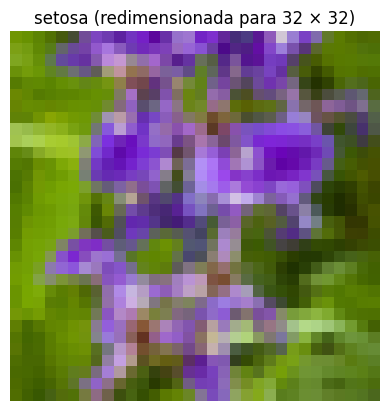

In [7]:
transform = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.ToTensor()
])

caminho_exemplo = listar_imagens(Path("dataset_iris/train/setosa"))[0]
imagem = datasets.folder.default_loader(str(caminho_exemplo))
imagem_tensor = transform(imagem)

print("Arquivo:", caminho_exemplo.name)
print("Formato do tensor:", imagem_tensor.shape)

plt.imshow(imagem_tensor.permute(1, 2, 0))
plt.title("setosa (redimensionada para 32 × 32)")
plt.axis("off")
plt.show()


Repare no formato `[3, 32, 32]`:

- `3` = canais de cor (`C`);
- `32` = altura (`H`);
- `32` = largura (`W`).

Aqui ainda estamos olhando **uma única imagem**, por isso não existe a dimensão de batch. Ela aparece quando agrupamos várias imagens para processá-las juntas.


## 4. Exercício 1 — Aplique o mesmo pipeline a outra imagem

Use a mesma ideia com uma fotografia de `versicolor`. A estrutura já está pronta; escolha uma imagem da pasta, aplique `transform` e confira se o resultado também tem formato `[3, 32, 32]`.


In [9]:
# Exercício 1
caminho_versicolor = listar_imagens(Path("dataset_iris/train/versicolor"))[0]

# TODO: abra a imagem usando datasets.folder.default_loader(...)
imagem_versicolor = datasets.folder.default_loader(str(caminho_versicolor))

# TODO: aplique o mesmo objeto `transform` criado acima
tensor_versicolor = transform(imagem_versicolor)

print("Formato do tensor:", tensor_versicolor.shape)


Formato do tensor: torch.Size([3, 32, 32])


## 5. Exemplo guiado 2 — O que significa o `B` de batch?

Até agora vimos uma imagem no formato `[C, H, W]`. Durante o treino, porém, não costumamos enviar uma imagem por vez. O `DataLoader` agrupa várias imagens em um **lote (batch)**.

![Diagrama de batch](https://drive.google.com/thumbnail?id=1PrQU4y16kVjpSUHczrS9fUJiQ7Y1GETP&sz=w1600)


Se `batch_size=8`, o lote tem formato:

```text
[B, C, H, W] = [8, 3, 32, 32]
```

O `B` **não é uma característica da imagem**. Ele só diz quantas imagens foram agrupadas naquela passagem pela rede. Cada uma das 8 imagens continua tendo `3 × 32 × 32` valores.


In [10]:
transform_dataset = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.ToTensor()
])

dataset_treino = datasets.ImageFolder("dataset_iris/train", transform=transform_dataset)
loader_treino = DataLoader(dataset_treino, batch_size=8, shuffle=True)

lote_imagens, lote_rotulos = next(iter(loader_treino))
B, C, H, W = lote_imagens.shape

print("Formato completo do lote:", lote_imagens.shape)
print(f"B = {B}: número de imagens no lote")
print(f"C = {C}: canais de cada imagem")
print(f"H = {H}: altura")
print(f"W = {W}: largura")
print("Formato dos rótulos:", lote_rotulos.shape, "-> um rótulo para cada imagem")


Formato completo do lote: torch.Size([8, 3, 32, 32])
B = 8: número de imagens no lote
C = 3: canais de cada imagem
H = 32: altura
W = 32: largura
Formato dos rótulos: torch.Size([8]) -> um rótulo para cada imagem


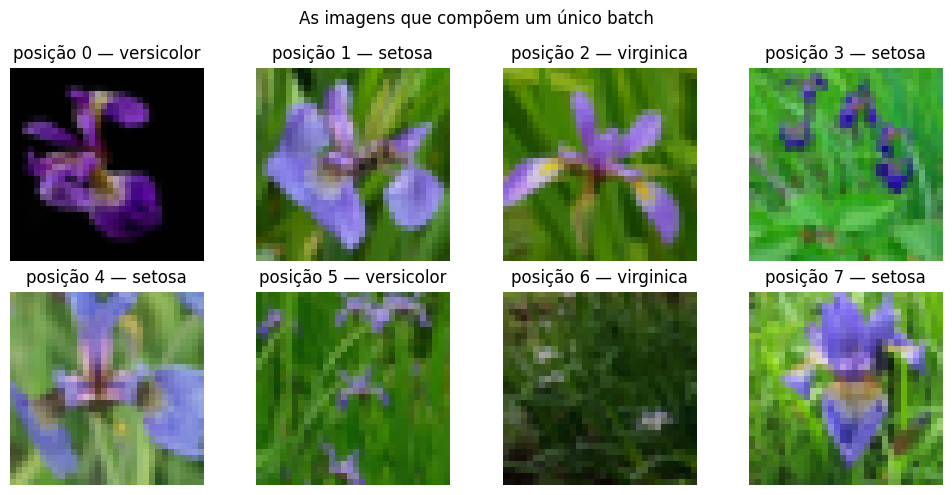

In [11]:
# Visualizando as imagens que realmente formam este batch
quantidade_para_mostrar = min(B, 8)
fig, eixos = plt.subplots(2, 4, figsize=(10, 5))

for i, eixo in enumerate(eixos.flat):
    if i < quantidade_para_mostrar:
        eixo.imshow(lote_imagens[i].permute(1, 2, 0))
        classe = dataset_treino.classes[lote_rotulos[i].item()]
        eixo.set_title(f"posição {i} — {classe}")
    eixo.axis("off")

plt.suptitle("As imagens que compõem um único batch")
plt.tight_layout()
plt.show()


Agora aplicamos a primeira convolução ao **lote inteiro**. O `B` continua aparecendo na primeira posição; o que a convolução muda é o número de canais/mapas de características.


In [12]:
conv1 = nn.Conv2d(in_channels=3, out_channels=8, kernel_size=3, padding=1)
mapas = conv1(lote_imagens)

print("Entrada da convolução: ", lote_imagens.shape, "= [B, 3, 32, 32]")
print("Saída da convolução:   ", mapas.shape, "= [B, 8, 32, 32]")


Entrada da convolução:  torch.Size([8, 3, 32, 32]) = [B, 3, 32, 32]
Saída da convolução:    torch.Size([8, 8, 32, 32]) = [B, 8, 32, 32]


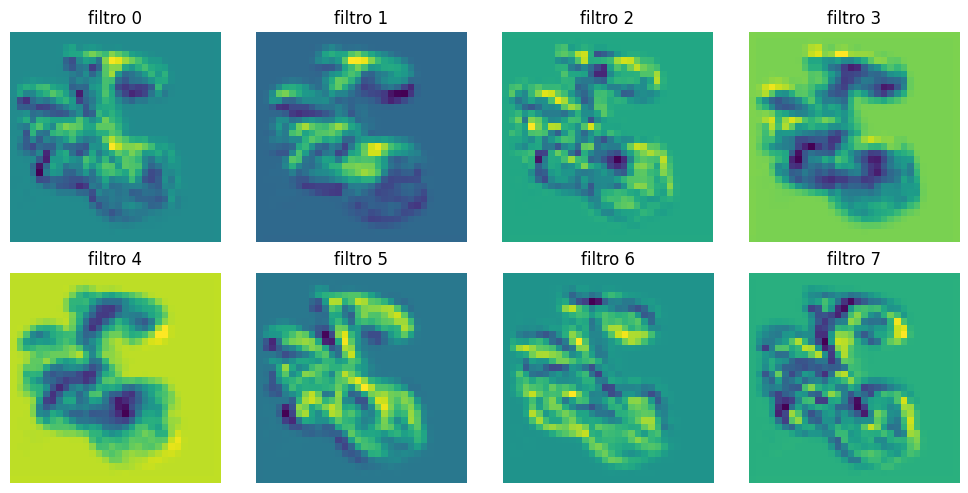

In [13]:
# Visualizando os 8 mapas de características da PRIMEIRA imagem do batch
fig, eixos = plt.subplots(2, 4, figsize=(10, 5))
primeira_imagem_mapas = mapas[0].detach()

for i, eixo in enumerate(eixos.flat):
    eixo.imshow(primeira_imagem_mapas[i], cmap="viridis")
    eixo.set_title(f"filtro {i}")
    eixo.axis("off")

plt.tight_layout()
plt.show()


## 6. Exercício 2 (texto) — Interpretando os mapas de características

Observe os 8 mapas acima. Escreva uma diferença visual que você percebe entre dois mapas específicos e o que isso sugere sobre o tipo de detalhe que cada filtro pode estar realçando.

**Sua resposta:**

Uma diferença visual que pode ser observada entre o **filtro 0** e o **filtro 3** é que o primeiro possui contornod mais finos, nítidos e bem delimitados. Já o segundo, possui áreas mais difusas e homogêneas. Isso sugere que cada filtro da camada funciona como um detector especializado, onde os filtros do primeiro tipo focam em mudanças mais abruptas de intensidade, enquanto os outros capturam padrões de superfície, transições de cor e texturas globais da imagem.


## 7. Exemplo guiado 3 — Stride e padding

Para comparar as configurações sem carregar um batch inteiro, selecionamos a primeira imagem do lote e usamos `unsqueeze(0)` para manter a dimensão `B=1`.


In [14]:
imagem_unica = lote_imagens[0].unsqueeze(0)  # [1, 3, 32, 32]: B = 1

conv_padding1 = nn.Conv2d(3, 8, 3, padding=1)
conv_padding0 = nn.Conv2d(3, 8, 3, padding=0)
conv_stride2  = nn.Conv2d(3, 8, 3, padding=1, stride=2)

saida_padding1 = conv_padding1(imagem_unica)
saida_padding0 = conv_padding0(imagem_unica)
saida_stride2  = conv_stride2(imagem_unica)

print("padding=1           ->", saida_padding1.shape)
print("padding=0           ->", saida_padding0.shape)
print("padding=1, stride=2 ->", saida_stride2.shape)


padding=1           -> torch.Size([1, 8, 32, 32])
padding=0           -> torch.Size([1, 8, 30, 30])
padding=1, stride=2 -> torch.Size([1, 8, 16, 16])


## 8. Exercício 3 (texto) — Diagnosticando stride e padding

A partir dos três formatos impressos, responda:

- Qual configuração produziu o **maior** mapa de saída?
- Qual produziu o **menor**?
- O valor de `B` mudou? Por que não?

**Sua resposta:**

- A configuração com `padding=1`
- A configuração com `padding=1`e `stride=2`
- Não, porque as operações convolucionais atuam de forma independente sobre os canais espaciais e filtros, sem alterações de quantidade de imagens.


## 9. Exemplo guiado 4 — Pooling

O pooling atua separadamente em cada imagem e em cada mapa de características. Por isso, novamente, `B` não muda: somente `H` e `W` são reduzidos.


Antes do pooling:  torch.Size([8, 8, 32, 32]) = [B, 8, 32, 32]
Depois do pooling: torch.Size([8, 8, 16, 16]) = [B, 8, 16, 16]


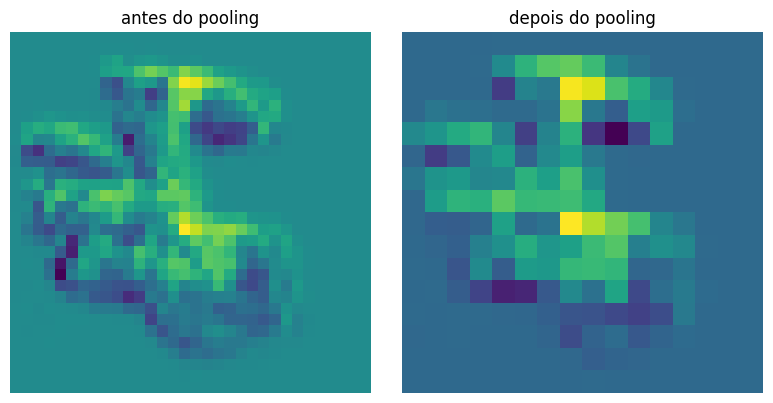

In [15]:
pool = nn.MaxPool2d(kernel_size=2, stride=2)
mapas_pooled = pool(mapas)

print("Antes do pooling: ", mapas.shape, "= [B, 8, 32, 32]")
print("Depois do pooling:", mapas_pooled.shape, "= [B, 8, 16, 16]")

fig, eixos = plt.subplots(1, 2, figsize=(8, 4))
eixos[0].imshow(mapas[0][0].detach(), cmap="viridis")
eixos[0].set_title("antes do pooling")
eixos[0].axis("off")

eixos[1].imshow(mapas_pooled[0][0].detach(), cmap="viridis")
eixos[1].set_title("depois do pooling")
eixos[1].axis("off")

plt.tight_layout()
plt.show()


## 10. Exemplo guiado 5 — Blocos convolucionais

Em CNNs mais profundas, várias camadas costumam ser agrupadas visualmente em **blocos convolucionais**. O objetivo é facilitar a leitura da arquitetura: em vez de enxergar uma lista enorme de camadas, enxergamos etapas maiores da rede.

Uma notação comum em diagramas é:

```text
Bloco 1
2× Conv64
+ MaxPool
```

Isso quer dizer que o bloco contém **duas convoluções que produzem 64 mapas de características**, seguidas de uma operação de max pooling. `Conv64` é uma abreviação de diagrama — não é uma função do PyTorch. Kernel, stride, padding e ativações podem aparecer em outra parte do desenho ou do código.

Vamos reproduzir a mesma ideia em escala menor usando o batch real do Iris. O bloco abaixo pode ser resumido como **`2× Conv8 + MaxPool`**. As ativações `ReLU` continuam presentes, embora diagramas compactos às vezes não as escrevam dentro do bloco.


In [16]:
# Exemplo de um bloco com duas convoluções antes do pooling
conv_bloco_1 = nn.Conv2d(3, 8, kernel_size=3, padding=1)
relu_bloco_1 = nn.ReLU()
conv_bloco_2 = nn.Conv2d(8, 8, kernel_size=3, padding=1)
relu_bloco_2 = nn.ReLU()
pool_bloco = nn.MaxPool2d(kernel_size=2, stride=2)

x_bloco = lote_imagens
print("Entrada do bloco:       ", x_bloco.shape)

x_bloco = relu_bloco_1(conv_bloco_1(x_bloco))
print("Após a 1ª Conv8 + ReLU:", x_bloco.shape)

x_bloco = relu_bloco_2(conv_bloco_2(x_bloco))
print("Após a 2ª Conv8 + ReLU:", x_bloco.shape)

x_bloco = pool_bloco(x_bloco)
print("Após o MaxPool:         ", x_bloco.shape)


Entrada do bloco:        torch.Size([8, 3, 32, 32])
Após a 1ª Conv8 + ReLU: torch.Size([8, 8, 32, 32])
Após a 2ª Conv8 + ReLU: torch.Size([8, 8, 32, 32])
Após o MaxPool:          torch.Size([8, 8, 16, 16])


## 11. Exercício 4 (texto) — Lendo um bloco convolucional

Use **os shapes impressos na célula anterior** para responder:

1. Quantas camadas `Conv2d` existem no bloco demonstrado?
2. Na primeira convolução, o número de canais muda de quanto para quanto?
3. Na segunda convolução, o número de canais muda ou permanece igual?
4. Qual operação foi responsável por reduzir `32 × 32` para `16 × 16`?
5. Como esse conjunto pode ser escrito na notação compacta usada em diagramas de arquitetura?

**Sua resposta:**

1. 2 camadas
2. Muda de 3 para 8
3. Permanece igual
4. MaxPool
5. `2x Conv8 + MaxPool`


## 12. Exemplo guiado 6 — `CNNIrisSimples` completa

Chegou a hora de juntar as peças. Antes de olhar o código, acompanhe o caminho da informação no diagrama.

![Diagrama da CNNIrisSimples](https://drive.google.com/thumbnail?id=1cbv4_-MXXTOt3aaQrFECqQrQ3NsjVEST&sz=w1600)

Observe principalmente duas coisas:

1. `B` permanece do começo ao fim: se entram 8 imagens, saem 8 vetores de logits;
2. as camadas de pooling reduzem `H` e `W`, enquanto as convoluções mudam o número de canais/mapas.

A classe abaixo usa nomes separados (`relu1`, `pool1`, `relu2`, `pool2`...) para que o resultado de `print(modelo_cnn)` fique fácil de comparar com o diagrama.


Também podemos ler a mesma arquitetura em dois blocos convolucionais: **Bloco 1 = `conv1 → relu1 → pool1`** e **Bloco 2 = `conv2 → relu2 → pool2`**. Aqui cada bloco tem apenas uma convolução; em redes mais profundas, como no exemplo anterior, um bloco pode ter duas ou mais convoluções antes do pooling.


In [17]:
class CNNIrisSimples(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 8, 3, padding=1)
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool2d(2, 2)

        self.conv2 = nn.Conv2d(8, 16, 3, padding=1)
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool2d(2, 2)

        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(16 * 8 * 8, 32)
        self.relu3 = nn.ReLU()
        self.fc2 = nn.Linear(32, 3)

    def forward(self, x):
        x = self.conv1(x)       # [B, 8, 32, 32]
        x = self.relu1(x)
        x = self.pool1(x)       # [B, 8, 16, 16]

        x = self.conv2(x)       # [B, 16, 16, 16]
        x = self.relu2(x)
        x = self.pool2(x)       # [B, 16, 8, 8]

        x = self.flatten(x)     # [B, 1024]
        x = self.fc1(x)         # [B, 32]
        x = self.relu3(x)
        x = self.fc2(x)         # [B, 3]
        return x

modelo_cnn = CNNIrisSimples()
print(modelo_cnn)


CNNIrisSimples(
  (conv1): Conv2d(3, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu1): ReLU()
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(8, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu2): ReLU()
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=1024, out_features=32, bias=True)
  (relu3): ReLU()
  (fc2): Linear(in_features=32, out_features=3, bias=True)
)


## 13. Exercício 5 (texto) — Lendo o `print(modelo_cnn)`

Não basta imprimir a rede: o `print` só é útil se você conseguir **ler o que ele está dizendo**. Compare a saída acima com o diagrama da Seção 12 e responda:

1. Quantas camadas `Conv2d` aparecem no modelo?
2. Quantas camadas `MaxPool2d` aparecem?
3. Quantas camadas `Linear` aparecem?
4. A primeira convolução recebe quantos canais (`in_channels`)? Quantos mapas ela produz (`out_channels`)?
5. Qual camada recebe `1024` valores e produz `32`?
6. A ordem das camadas impressas bate com o diagrama? Cite pelo menos um trecho da sequência para justificar.
7. Se agruparmos a CNN em blocos, quais camadas formam o **primeiro bloco convolucional** e quais formam o **segundo**?
8. No diagrama aparecem vários shapes com `B`. O valor de `B` faz parte da definição de `Conv2d` ou `Linear` no `print`? Explique por que o modelo pode aceitar batches com tamanhos diferentes.

**Sua resposta:**

1. 2 camadas
2. 2 camadas
3. 2 camadas
4. A primeira recebe 3 e a segunda produz 8
5. A camada `fc1`
6. Sim, a ordem bate com o diagrama. O primeiro poolimg vem antes da segunda convolução, como apresentado no diagrama.
7. Primeiro bloco: `conv1 -> relu1 -> pool1`. Segundo bloco: `conv2 -> relu2 -> pool2.
8. Não. `B` não se faz aparemte na parte de definição das camadas. O modelo pode aceitar batches de tamanhos diferentes porque os pesos não dependem de quantas imagens entram, e cada imagem é processada independentemente uma da outra.


### Preparando os `DataLoader`s para o treino

A preparação abaixo usa exatamente as pastas balanceadas construídas no início. `shuffle=True` é usado somente no treino, porque ali queremos variar a ordem dos exemplos a cada época.


In [18]:
transform_padrao = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.ToTensor()
])

dataset_treino = datasets.ImageFolder("dataset_iris/train", transform=transform_padrao)
dataset_val    = datasets.ImageFolder("dataset_iris/val",   transform=transform_padrao)
dataset_teste  = datasets.ImageFolder("dataset_iris/test",  transform=transform_padrao)

loader_treino = DataLoader(dataset_treino, batch_size=8, shuffle=True)
loader_val    = DataLoader(dataset_val,    batch_size=8, shuffle=False)
loader_teste  = DataLoader(dataset_teste,  batch_size=8, shuffle=False)

print("Classes:", dataset_treino.classes)
print("Tamanho treino/val/teste:", len(dataset_treino), len(dataset_val), len(dataset_teste))


Classes: ['setosa', 'versicolor', 'virginica']
Tamanho treino/val/teste: 138 30 33


### Treinando a CNN

O ciclo é o mesmo que você já viu na M04-L02. A diferença é o formato de `imagens`: agora cada batch é `[B, C, H, W]`.


In [19]:
funcao_perda = nn.CrossEntropyLoss()
otimizador = optim.Adam(modelo_cnn.parameters(), lr=0.001)

num_epocas = 50
historico = {"epoca": [], "perda_treino": [], "acc_treino": [], "perda_val": [], "acc_val": []}

for epoca in range(1, num_epocas + 1):
    modelo_cnn.train()
    perda_total, acertos, total = 0.0, 0, 0

    for imagens, rotulos in loader_treino:
        otimizador.zero_grad()
        saidas = modelo_cnn(imagens)
        perda = funcao_perda(saidas, rotulos)
        perda.backward()
        otimizador.step()

        perda_total += perda.item() * imagens.size(0)
        acertos += (saidas.argmax(dim=1) == rotulos).sum().item()
        total += imagens.size(0)

    perda_treino = perda_total / total
    acc_treino = acertos / total

    modelo_cnn.eval()
    perda_total, acertos, total = 0.0, 0, 0
    with torch.no_grad():
        for imagens, rotulos in loader_val:
            saidas = modelo_cnn(imagens)
            perda = funcao_perda(saidas, rotulos)
            perda_total += perda.item() * imagens.size(0)
            acertos += (saidas.argmax(dim=1) == rotulos).sum().item()
            total += imagens.size(0)

    perda_val = perda_total / total
    acc_val = acertos / total

    historico["epoca"].append(epoca)
    historico["perda_treino"].append(perda_treino)
    historico["acc_treino"].append(acc_treino)
    historico["perda_val"].append(perda_val)
    historico["acc_val"].append(acc_val)

    print(f"Época {epoca:2d} | perda treino {perda_treino:.4f} | acc treino {acc_treino:.4f} "
          f"| perda val {perda_val:.4f} | acc val {acc_val:.4f}")


Época  1 | perda treino 1.1177 | acc treino 0.3261 | perda val 1.0934 | acc val 0.3333
Época  2 | perda treino 1.0945 | acc treino 0.3333 | perda val 1.0871 | acc val 0.3667
Época  3 | perda treino 1.0915 | acc treino 0.3841 | perda val 1.0828 | acc val 0.5000
Época  4 | perda treino 1.0784 | acc treino 0.4420 | perda val 1.0695 | acc val 0.4000
Época  5 | perda treino 1.0696 | acc treino 0.4420 | perda val 1.0539 | acc val 0.5667
Época  6 | perda treino 1.0579 | acc treino 0.4275 | perda val 1.0454 | acc val 0.3667
Época  7 | perda treino 1.0418 | acc treino 0.4565 | perda val 1.0354 | acc val 0.4333
Época  8 | perda treino 1.0223 | acc treino 0.5072 | perda val 1.0223 | acc val 0.4333
Época  9 | perda treino 0.9902 | acc treino 0.5072 | perda val 1.0765 | acc val 0.4333
Época 10 | perda treino 0.9568 | acc treino 0.5000 | perda val 1.0005 | acc val 0.5000
Época 11 | perda treino 0.9385 | acc treino 0.5362 | perda val 0.9825 | acc val 0.5000
Época 12 | perda treino 0.9090 | acc treino

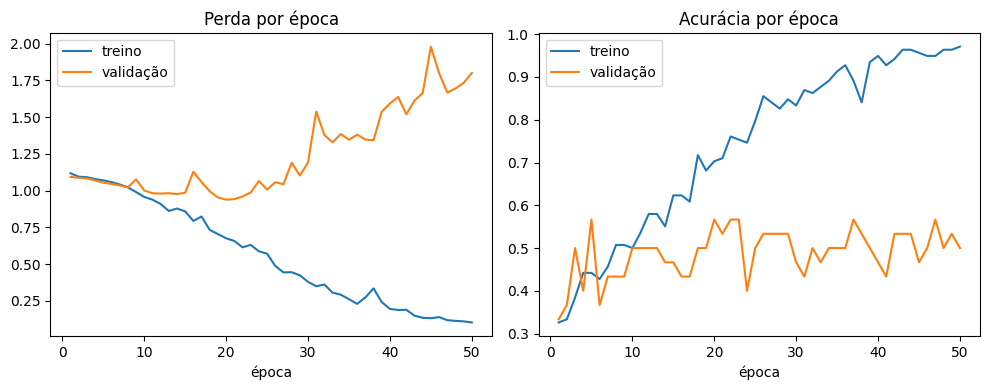

In [20]:
df_historico = pd.DataFrame(historico)
df_historico.to_csv("historico_cnn_iris_simples.csv", index=False)

fig, eixos = plt.subplots(1, 2, figsize=(10, 4))
eixos[0].plot(df_historico["epoca"], df_historico["perda_treino"], label="treino")
eixos[0].plot(df_historico["epoca"], df_historico["perda_val"], label="validação")
eixos[0].set_title("Perda por época")
eixos[0].set_xlabel("época")
eixos[0].legend()

eixos[1].plot(df_historico["epoca"], df_historico["acc_treino"], label="treino")
eixos[1].plot(df_historico["epoca"], df_historico["acc_val"], label="validação")
eixos[1].set_title("Acurácia por época")
eixos[1].set_xlabel("época")
eixos[1].legend()

plt.tight_layout()
plt.show()


### Exercício — O que aconteceu durante o treinamento?

Observe as curvas de perda e acurácia de **treino** e **validação** geradas acima.

Compare principalmente o comportamento das duas partes ao longo das épocas e responda:

1. A acurácia de treino continua melhorando durante o treinamento. O mesmo acontece de forma consistente com a acurácia de validação?

2. Compare também as perdas de treino e validação. O que acontece com a perda de validação enquanto a perda de treino continua diminuindo?

3. Com base nessas evidências, o modelo parece estar **generalizando bem para dados que não foram usados no treinamento** ou está aprendendo excessivamente os exemplos de treino? Justifique usando os valores ou as curvas observadas.

4. Considerando esse comportamento, treinar por mais épocas necessariamente melhoraria o modelo? Explique.

**Sua explicação:**

1. A acurácia de treino subiu de quase 0 (0.3) para 1.0. A de validação acabou não tendo muitas mudanças, oscilando muito e não passando de 0.6, sem acompanhar de forma consistente o treino.
2. A perda de treino continuou caindo, mas a de validação voltou a subir a partir da época 10.
3. Se as curvas divergirem assim, o modelo está memorizando o treino (overfitting) em vez de generalizar. Isso pode ser visto pela distância gigante entre a acurácia de nosso treino e de nossa validação.
4. Não. Treinar mais tende a aumentar o overfitting, e uma acurácia de validação que já estagnou não melhora só com mais épocas. Seriam mais úteis early stopping, regularização (dropout, weight decay) ou data augmentation.


## 14. Exercício 6 (código) — Calculando o número de entradas de `nn.Linear`

O diagrama e o `forward` mostram que, depois do segundo pooling, cada imagem está representada por `[16, 8, 8]`. Complete **somente o cálculo** abaixo para descobrir quantos valores chegam a `fc1`.


In [21]:
canais = 16
altura = 8
largura = 8

numero_de_entradas = ...  # TODO: use canais, altura e largura
print("Número de entradas da primeira camada nn.Linear:", numero_de_entradas)



Número de entradas da primeira camada nn.Linear: Ellipsis


## 15. Erro comum 1 — `flatten` e `nn.Linear` incompatíveis

A célula abaixo reproduz de propósito um erro comum: declarar `fc1` com um número de entradas diferente do tamanho real produzido por `flatten`.


In [22]:
class CNNIrisComErroDimensao(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 8, 3, padding=1)
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool2d(2, 2)
        self.conv2 = nn.Conv2d(8, 16, 3, padding=1)
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool2d(2, 2)
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(16 * 16 * 16, 32)  # ERRADO de propósito
        self.fc2 = nn.Linear(32, 3)

    def forward(self, x):
        x = self.pool1(self.relu1(self.conv1(x)))
        x = self.pool2(self.relu2(self.conv2(x)))
        x = self.flatten(x)
        x = self.fc1(x)
        return self.fc2(x)

modelo_com_erro = CNNIrisComErroDimensao()
imagens_exemplo, _ = next(iter(loader_treino))

try:
    modelo_com_erro(imagens_exemplo)
except RuntimeError as erro:
    print("Erro do PyTorch:")
    print(erro)


Erro do PyTorch:
mat1 and mat2 shapes cannot be multiplied (8x1024 and 4096x32)


## 16. Exercício de correção 1 (texto)

Explique por que o erro acima ocorre e qual deve ser o número correto de entradas de `fc1`.

**Sua resposta:**

`flatten` acaba achatanto [B, 16, 8, 8] em [B, 1024], porque 16 * 8 * 8 = 1024. O código declarou `fc1 = Linear(16*16*16, 32)`, isso significa que ele esperava 4096 entradas. A multiplicação das matrizes falha porque 1024 é diferente de 4096. O erro foi usar 16 vezes16 para H vezes W, que é o tamanho antes do segundo pooling. Depois dele são 8 vezes 8. O valor correto é `nn.Linear(16 * 8 * 8, 32)`, isto é, 1024 entradas.


## 17. Erro comum 2 — Imagem em escala de cinza e `in_channels`

Uma CNN precisa saber **quantos canais existem em cada imagem**. No nosso pipeline principal, `ImageFolder` carrega as imagens como RGB e o batch tem `C=3`, por isso usamos:

```python
nn.Conv2d(in_channels=3, ...)
```

Mas imagine que seu pipeline entregue uma imagem em escala de cinza. Nesse caso o tensor tem somente **1 canal**: `[B, 1, H, W]`. Se a primeira convolução continuar esperando 3 canais, o PyTorch gera um erro.

A célula abaixo reproduz exatamente esse problema transformando um batch RGB em uma representação de 1 canal.


In [23]:
# Simulando a situação em que o pipeline entrega imagens em escala de cinza
batch_cinza = lote_imagens.mean(dim=1, keepdim=True)  # [B, 1, 32, 32]
print("Batch em escala de cinza:", batch_cinza.shape)

conv_esperando_rgb = nn.Conv2d(in_channels=3, out_channels=8, kernel_size=3, padding=1)

try:
    conv_esperando_rgb(batch_cinza)
except RuntimeError as erro:
    print("\nErro do PyTorch:")
    print(erro)


Batch em escala de cinza: torch.Size([8, 1, 32, 32])

Erro do PyTorch:
Given groups=1, weight of size [8, 3, 3, 3], expected input[8, 1, 32, 32] to have 3 channels, but got 1 channels instead


## 18. Exercício de correção 2 — Quantos canais a convolução deve receber?

Observe o shape `[B, 1, 32, 32]` e a mensagem de erro. Faça uma **modificação pontual** na célula abaixo para criar uma convolução compatível com imagens em escala de cinza.

Depois responda: **por que `in_channels=1` é a escolha correta nesse caso?**


In [24]:
# TODO: corrija somente o valor de in_channels
conv_cinza = nn.Conv2d(in_channels=3, out_channels=8, kernel_size=3, padding=1)

saida_cinza = conv_cinza(batch_cinza)
print("Saída após a convolução corrigida:", saida_cinza.shape)


RuntimeError: Given groups=1, weight of size [8, 3, 3, 3], expected input[8, 1, 32, 32] to have 3 channels, but got 1 channels instead

**Sua explicação:**

O nosso `in_channels` precisa ser igualzinho ao número de canais do tensor de entrada. Ademais, temos que uma imagem em escala de cinza tem um único canal. Cada filtro tem forma `[in_channels, 3, 3]`, então com `in_channels=3`, ele espera 3 canais, e o PyTorch acusa erro ao receber somente 1. Com `in_channels=1` os filtros casam com a entrada, e a saída é `[B, 8, 32, 32]`.


## 19. Desafio extra (opcional) — Reduzindo as imagens para `16 × 16`

O objetivo é observar a relação entre resolução de entrada, tamanho interno da rede e desempenho. O código é guiado; você só precisa executar e interpretar.


In [25]:
class CNNIrisSimples16(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 8, 3, padding=1)
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool2d(2, 2)
        self.conv2 = nn.Conv2d(8, 16, 3, padding=1)
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool2d(2, 2)
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(16 * 4 * 4, 32)
        self.relu3 = nn.ReLU()
        self.fc2 = nn.Linear(32, 3)

    def forward(self, x):
        x = self.pool1(self.relu1(self.conv1(x)))
        x = self.pool2(self.relu2(self.conv2(x)))
        x = self.flatten(x)
        x = self.relu3(self.fc1(x))
        return self.fc2(x)

# A preparação/treino completo desta versão pode reutilizar o mesmo laço mostrado acima,
# trocando apenas o transform para Resize((16, 16)) e o modelo para CNNIrisSimples16().
print(CNNIrisSimples16())


CNNIrisSimples16(
  (conv1): Conv2d(3, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu1): ReLU()
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(8, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu2): ReLU()
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=256, out_features=32, bias=True)
  (relu3): ReLU()
  (fc2): Linear(in_features=32, out_features=3, bias=True)
)


**Sua análise (texto):** que mudanças você espera no tempo de treino e na quantidade de detalhes visuais disponíveis quando a imagem cai de `32 × 32` para `16 × 16`?

O nosso tempo de treino deve cair. A imagem tem 4 vezes menos pixels, então as convoluções fazem menos operações, e `fc1` passa de 1024 para 256 entradas (ou seja, temos menos parâmetros). Alguns detalhes visuais que podemos perceber são a redução de resolução, que perde as bordas finas e as suas texturas, e as pétalas que acabam ficando menos nítidas. Como as espécies diferem muito não somente na cor, mas também na forma geral, é possível que a acurácia caia pouco ou nada.


## 20. Avaliação final e comparação com a MLP da M04-L02

Agora usamos o conjunto de teste, que ficou separado desde a preparação inicial.


In [26]:
modelo_cnn.eval()
acertos, total = 0, 0

with torch.no_grad():
    for imagens, rotulos in loader_teste:
        saidas = modelo_cnn(imagens)
        acertos += (saidas.argmax(dim=1) == rotulos).sum().item()
        total += imagens.size(0)

acc_teste_cnn = acertos / total
print(f"Acurácia de teste da CNNIrisSimples: {acc_teste_cnn:.4f}")


Acurácia de teste da CNNIrisSimples: 0.3939


In [27]:
tabela_comparativa = resultados_m04_l02.copy()
tabela_comparativa = pd.concat([
    tabela_comparativa,
    pd.DataFrame([{"modelo": "CNNIrisSimples (imagem direta)", "acuracia_teste": acc_teste_cnn}])
], ignore_index=True)

nome_comparacao = "comparacao_cnn_vs_mlp_m04l03.csv"
tabela_comparativa.to_csv(nome_comparacao, index=False)
caminho_comparacao_drive = Path('/content/drive/MyDrive/dados_modulo_04') / nome_comparacao
caminho_comparacao_drive.parent.mkdir(parents=True, exist_ok=True)
shutil.copy2(nome_comparacao, caminho_comparacao_drive)
print("Comparação da M04-L03 salva em:", caminho_comparacao_drive)
tabela_comparativa


Comparação da M04-L03 salva em: /content/drive/MyDrive/dados_modulo_04/comparacao_cnn_vs_mlp_m04l03.csv


,modelo,acuracia_teste
0,LogisticRegression,NaN
1,DecisionTreeClassifier,NaN
2,KNeighborsClassifier,NaN
3,MLP escolhida — Mais larga (5→16→3),1.000000
4,MLP escolhida regularizada — Mais larga (5→16→3),1.000000
5,CNNIrisSimples (imagem direta),0.393939


## 21. Exercício final — Diagnóstico dirigido

Use as evidências produzidas pelo próprio notebook. Consulte as seções indicadas antes de responder.

1. Na **Seção 5**, consulte a saída de `lote_imagens.shape` do primeiro batch. Cite `B`, `C`, `H` e `W` e explique o significado de cada valor.
2. Na **Seção 5**, consulte os shapes impressos antes e depois de `conv1`. O que mudou? O que permaneceu igual?
3. Na **Seção 9**, consulte os shapes impressos antes e depois do pooling. O `B` mudou? E `H`/`W`?
4. Na **Seção 10**, consulte as saídas do bloco `2× Conv8 + MaxPool`. Quantas convoluções há no bloco e qual operação reduz `H/W`?
5. Na **Seção 12**, consulte o diagrama da `CNNIrisSimples` e a saída de `print(modelo_cnn)`. Cite a sequência entre `conv1` e `conv2` e explique por que ela faz sentido.
6. Na **Seção 17**, consulte o shape do batch em escala de cinza e a mensagem de erro. Qual dimensão do tensor revelou que `in_channels=3` estava errado?
7. Na célula do **histórico de treino, antes da Seção 14**, consulte `df_historico` e compare `acc_treino` e `acc_val` da primeira e da última época. O que mudou durante o treinamento?
8. Na **Seção 20**, consulte `tabela_comparativa`. Compare numericamente a CNN com a MLP da M04-L02. Qual foi melhor no teste? Indique a linha da MLP escolhida que você usou na comparação.

**Sua resposta:**

1. B = 8 é o número de imagens do lote, C = 3 são os canais de cor, H = 32 é a altura e W = 32 a largura.
2. Mudou o número de canais (3 para 8 mapas). Permaneceram B, H e W.
3. B não mudou (nem os canais). H e W caíram pela metade.
4. O bloco tem 2 convoluções `Conv8`, e o `MaxPool` é quem reduz `H/W`
5. A sequência é `conv1, relu1, pool1, conv2, relu2 e pool2`. Ela faz sentido porque a convolução extrai mapas, a ReLU adiciona não linearidade e o pooling reduz a resolução. A segunda convolução então enxerga padrões mais amplos (campo receptivo maior) e aumenta os canais (8 para 16) para compensar a perda de resolução espacial.
6. A dimensão de canais (posição 1): o batch cinza é [B, 1, 32, 32], e a convolução esperava 3 canais.
7. A acurácia foi de 0.3 na época 1 para 1.0 na época 50. Já a acurácia de validação foi de 0.3 para 0.5. A diferença foi gritante.
8. A CNNIrisSimples obteve acurácia de teste de 0.39, e a MLP da M04-L02 obteve 1.0. Portanto, A Iris Simples foi melhor. Como os testes têm tamanhos diferentes e pequenos (10 amostras na L02 e 33 imagens na L03), a diferença deve ser interpretada com cautela.


## 22. Reflexão final

Compare a acurácia de teste da `CNNIrisSimples` com a MLP da M04-L02. A CNN foi melhor, pior ou parecida? Considere também que, nesta lição, o conjunto de imagens foi explicitamente balanceado usando a quantidade da menor classe. Como isso ajuda a tornar a comparação entre as classes mais justa dentro deste laboratório?

**Sua resposta:**
A MLP escolhida na M04-L02 (5 → 16 → 3, a nossa selecionada pela validação) obteve acurácia de teste de 1.0, e a versão regularizada também. A CNNIrisSimples obteve 1.0. Portanto, a CNN foi melhor que a MLP neste laboratório, mas a comparação deve ser lida com cautela. Os testes são conjuntos diferentes e pequenos (10 amostras na L02 e 33 imagens na L03, em que cada imagem vale cerca de 3 pontos percentuais). Além disso, a MLP recebe 5 features já resumidas e informativas, enquanto a CNN parte dos pixels e precisa aprender sozinha os padrões visuais com apenas 138 imagens de treino.

O balanceamento ajuda a tornar a comparação mais justa. O conjunto original era desbalanceado (setosa 67, versicolor 269, virginica 85); sem correção, um modelo poderia acertar muito favorecendo a classe majoritária. Com 67 imagens por classe, as três espécies têm o mesmo peso no treino e no teste, e o acaso corresponde a cerca de 33%. O custo é descartar imagens de versicolor (de 269 para 67).



## 23. Checklist final

* [x] Baixei (automaticamente ou manualmente) o Iris Computer Vision do Kaggle.
* [x] Conferi quantas imagens existem em cada classe antes do balanceamento.
* [x] Entendi por que usamos o número de imagens da menor classe em todas as classes.
* [x] Criei as partições balanceadas `train`, `val` e `test`.
* [x] Entendo a diferença entre `[C, H, W]` de uma imagem e `[B, C, H, W]` de um batch.
* [x] Visualizei as imagens que compõem um batch e interpretei `B`, `C`, `H` e `W`.
* [x] Observei os mapas de características de uma convolução.
* [x] Diagnostiquei o efeito de stride, padding e pooling sobre os shapes.
* [x] Sei interpretar um bloco convolucional e uma notação compacta como `2× Conv64 + MaxPool`.
* [x] Comparei o `print(modelo_cnn)` com o diagrama da arquitetura.
* [x] Calculei o número de entradas de `fc1`.
* [x] Diagnostiquei o erro de incompatibilidade entre `flatten` e `Linear`.
* [x] Diagnostiquei o erro de canal em uma imagem em escala de cinza e corrigi `in_channels` para `1`.
* [x] Treinei a `CNNIrisSimples` e acompanhei perda/acurácia.
* [x] Avaliei a CNN no teste e comparei com a MLP da M04-L02.
* [x] Preenchi a reflexão final.

* [x] Salvei `dataset_iris/train`, `val` e `test` no Drive para reutilizar nas próximas lições.


## 24. Orientação de entrega

Salve o notebook com todas as células executadas (`M04-L03_lab_SEUNOME.ipynb`) e envie-o conforme orientado pela equipe. Mantenha também os arquivos:

- `historico_cnn_iris_simples.csv`;
- `comparacao_cnn_vs_mlp_m04l03.csv` (também salvo no Drive em `dados_modulo_04/`, para a M04-L04).

Não é necessário enviar o `.zip` original do Kaggle nem a pasta `iris_raw/`, a menos que a equipe peça explicitamente.
